# Household Electricity Forecasting: LSTM

Kept in a separate notebook so that PyTorch and XGBoost are not loaded in the same kernel (their OpenMP runtimes conflict on macOS). Predictions are saved to `data/lstm_predictions.csv` and compared with the other models in `02_modeling.ipynb`.

In [1]:
import time
import copy

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.6,
    "lines.linewidth": 1.2,
    "font.size": 10,
})
BLUE = "#2a78d6"
ORANGE = "#eb6834"

## Load prepared data

In [2]:
model_df = pd.read_csv("data/model_df.csv", index_col="datetime", parse_dates=True)
hourly = pd.read_csv("data/hourly.csv", index_col="datetime", parse_dates=True)

train = model_df[model_df["split"] == "train"]
val = model_df[model_df["split"] == "val"]
test = model_df[model_df["split"] == "test"]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {len(part):>6} 行   {part.index.min()}  到  {part.index.max()}")

Train        23370 行   2006-12-23 18:00:00  到  2009-09-06 23:00:00
Validation    5008 行   2009-09-07 00:00:00  到  2010-04-12 19:00:00
Test          5009 行   2010-04-12 20:00:00  到  2010-11-26 20:00:00


## Build input sequences (previous 168 hours)

Numeric inputs are standardised with the training-period mean and standard deviation only. Missing hours are filled with 0 (the training mean) and flagged with `is_missing`.

In [3]:
SEQ_LEN = 168

numeric_cols = ["Global_active_power", "Global_reactive_power", "Voltage",
                "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

seq_data = hourly[numeric_cols].copy()
seq_data["is_missing"] = seq_data["Global_active_power"].isna().astype(float)
seq_data["hour_sin"] = np.sin(2 * np.pi * seq_data.index.hour / 24)
seq_data["hour_cos"] = np.cos(2 * np.pi * seq_data.index.hour / 24)
seq_data["dow_sin"] = np.sin(2 * np.pi * seq_data.index.day_of_week / 7)
seq_data["dow_cos"] = np.cos(2 * np.pi * seq_data.index.day_of_week / 7)
seq_data["month_sin"] = np.sin(2 * np.pi * (seq_data.index.month - 1) / 12)
seq_data["month_cos"] = np.cos(2 * np.pi * (seq_data.index.month - 1) / 12)
seq_data["is_weekend"] = (seq_data.index.day_of_week >= 5).astype(float)

train_period = seq_data.index <= train.index.max()
train_mean = seq_data.loc[train_period, numeric_cols].mean()
train_std = seq_data.loc[train_period, numeric_cols].std()

seq_data[numeric_cols] = (seq_data[numeric_cols] - train_mean) / train_std
seq_data = seq_data.fillna(0)

power_mean = train_mean["Global_active_power"]
power_std = train_std["Global_active_power"]

print("每个时间步的输入特征数:", seq_data.shape[1])

每个时间步的输入特征数: 14


In [4]:
values = seq_data.to_numpy(dtype=np.float32)

def make_sequences(part):
    positions = seq_data.index.get_indexer(part.index)
    X = np.stack([values[p - SEQ_LEN:p] for p in positions])
    y = ((part["target"].to_numpy() - power_mean) / power_std).astype(np.float32)
    return torch.from_numpy(X), torch.from_numpy(y)

X_train_seq, y_train_seq = make_sequences(train)
X_val_seq, y_val_seq = make_sequences(val)
X_test_seq, y_test_seq = make_sequences(test)

print("训练集:", tuple(X_train_seq.shape))
print("验证集:", tuple(X_val_seq.shape))
print("测试集:", tuple(X_test_seq.shape))

训练集: (23370, 168, 14)
验证集: (5008, 168, 14)
测试集: (5009, 168, 14)


## Model: input sequence → one LSTM layer → dropout → dense output

In [5]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden_size=64, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last_step = lstm_out[:, -1, :]
        return self.output(self.dropout(last_step)).squeeze(-1)

lstm_model = LSTMForecaster(n_features=X_train_seq.shape[2])
train_loader = DataLoader(TensorDataset(X_train_seq, y_train_seq), batch_size=256, shuffle=True)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=1e-3)

print(lstm_model)
print("可训练参数个数:", sum(p.numel() for p in lstm_model.parameters()))

LSTMForecaster(
  (lstm): LSTM(14, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=64, out_features=1, bias=True)
)
可训练参数个数: 20545


## Speed check (one batch)

In [6]:
test_model = LSTMForecaster(n_features=X_train_seq.shape[2])
xb, yb = next(iter(train_loader))

t0 = time.perf_counter()
loss_fn(test_model(xb), yb).backward()
batch_time = time.perf_counter() - t0

print(f"一个 batch 用时 {batch_time:.2f} 秒，估计一轮约 {batch_time * len(train_loader) / 60:.1f} 分钟")
print("PyTorch 使用的 CPU 线程数:", torch.get_num_threads())

一个 batch 用时 0.34 秒，估计一轮约 0.5 分钟
PyTorch 使用的 CPU 线程数: 4


## Training with early stopping on validation loss

In [7]:
MAX_EPOCHS = 50
PATIENCE = 5

history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

start = time.perf_counter()
for epoch in range(1, MAX_EPOCHS + 1):
    lstm_model.train()
    batch_losses = []
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(lstm_model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    train_loss = np.mean(batch_losses)

    lstm_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(lstm_model(X_val_seq), y_val_seq).item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch:>2}   train loss {train_loss:.4f}   val loss {val_loss:.4f}   已用 {time.perf_counter() - start:.0f} 秒")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(lstm_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"验证集 loss 连续 {PATIENCE} 轮没有改善，提前停止")
            break
lstm_time = time.perf_counter() - start

lstm_model.load_state_dict(best_state)
best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"训练耗时: {lstm_time:.1f} 秒，使用第 {best_epoch} 轮的模型")

Epoch  1   train loss 0.6510   val loss 0.4400   已用 11 秒
Epoch  2   train loss 0.4388   val loss 0.3937   已用 20 秒
Epoch  3   train loss 0.4012   val loss 0.3631   已用 34 秒
Epoch  4   train loss 0.3793   val loss 0.3493   已用 46 秒
Epoch  5   train loss 0.3647   val loss 0.3474   已用 56 秒
Epoch  6   train loss 0.3557   val loss 0.3365   已用 67 秒
Epoch  7   train loss 0.3471   val loss 0.3322   已用 76 秒
Epoch  8   train loss 0.3455   val loss 0.3329   已用 86 秒
Epoch  9   train loss 0.3381   val loss 0.3342   已用 96 秒
Epoch 10   train loss 0.3354   val loss 0.3244   已用 105 秒
Epoch 11   train loss 0.3336   val loss 0.3271   已用 115 秒
Epoch 12   train loss 0.3272   val loss 0.3284   已用 124 秒
Epoch 13   train loss 0.3290   val loss 0.3255   已用 133 秒
Epoch 14   train loss 0.3217   val loss 0.3260   已用 143 秒
Epoch 15   train loss 0.3196   val loss 0.3240   已用 152 秒
Epoch 16   train loss 0.3153   val loss 0.3211   已用 162 秒
Epoch 17   train loss 0.3152   val loss 0.3246   已用 171 秒
Epoch 18   train loss 0

## Training and validation loss curves

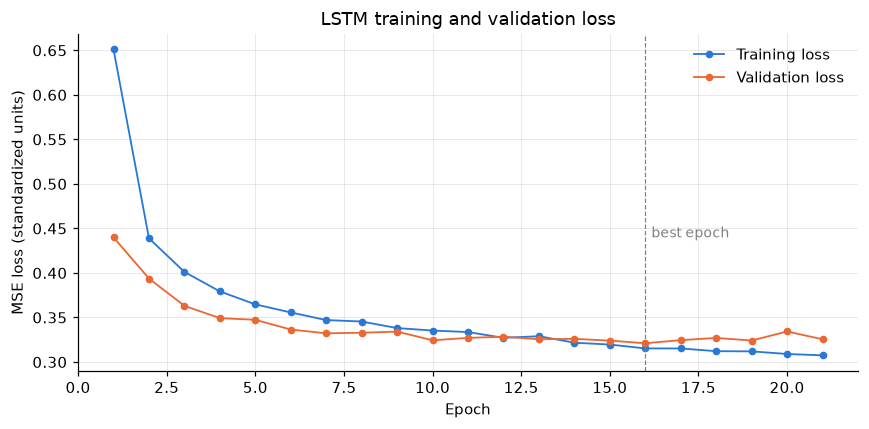

In [8]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, history["train_loss"], color=BLUE, marker="o", markersize=4, label="Training loss")
ax.plot(epochs, history["val_loss"], color=ORANGE, marker="o", markersize=4, label="Validation loss")
ax.axvline(best_epoch, color="grey", linestyle="--", linewidth=0.8)
ax.annotate("best epoch", xy=(best_epoch, max(history["val_loss"])), xytext=(4, 0),
            textcoords="offset points", fontsize=9, color="grey")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss (standardized units)")
ax.set_title("LSTM training and validation loss")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Predictions and save

In [9]:
lstm_model.eval()
with torch.no_grad():
    val_pred = lstm_model(X_val_seq).numpy() * power_std + power_mean
    test_pred = lstm_model(X_test_seq).numpy() * power_std + power_mean

lstm_predictions = pd.concat([
    pd.DataFrame({"split": "val", "prediction": val_pred}, index=val.index),
    pd.DataFrame({"split": "test", "prediction": test_pred}, index=test.index),
])
lstm_predictions.to_csv("data/lstm_predictions.csv")
pd.DataFrame(history).assign(train_time_s=lstm_time).to_csv("data/lstm_history.csv", index_label="epoch")

val_mae = np.mean(np.abs(val["target"].to_numpy() - val_pred))
test_mae = np.mean(np.abs(test["target"].to_numpy() - test_pred))
print(f"LSTM  Val MAE: {val_mae:.3f}   Test MAE: {test_mae:.3f}")
print("预测结果已保存到 data/lstm_predictions.csv")

LSTM  Val MAE: 0.368   Test MAE: 0.325
预测结果已保存到 data/lstm_predictions.csv
